<a href="https://colab.research.google.com/github/Aizereshka/happiness-score-prediction/blob/main/happiness_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [48]:
import pandas as pd

In [49]:
df=pd.read_csv("2015.csv")
print(df.shape)
print(df.head())
df.info()

(158, 12)
       Country          Region  Happiness Rank  Happiness Score  \
0  Switzerland  Western Europe               1            7.587   
1      Iceland  Western Europe               2            7.561   
2      Denmark  Western Europe               3            7.527   
3       Norway  Western Europe               4            7.522   
4       Canada   North America               5            7.427   

   Standard Error  Economy (GDP per Capita)   Family  \
0         0.03411                   1.39651  1.34951   
1         0.04884                   1.30232  1.40223   
2         0.03328                   1.32548  1.36058   
3         0.03880                   1.45900  1.33095   
4         0.03553                   1.32629  1.32261   

   Health (Life Expectancy)  Freedom  Trust (Government Corruption)  \
0                   0.94143  0.66557                        0.41978   
1                   0.94784  0.62877                        0.14145   
2                   0.87464  0.64938 

In [50]:
df.describe()

,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000
mean,79.493671,5.375734,0.047885,0.846137,0.991046,0.630259,0.428615,0.143422,0.237296,2.098977
std,45.754363,1.145010,0.017146,0.403121,0.272369,0.247078,0.150693,0.120034,0.126685,0.553550
min,1.000000,2.839000,0.018480,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.328580
25%,40.250000,4.526000,0.037268,0.545808,0.856823,0.439185,0.328330,0.061675,0.150553,1.759410
50%,79.500000,5.232500,0.043940,0.910245,1.029510,0.696705,0.435515,0.107220,0.216130,2.095415
75%,118.750000,6.243750,0.052300,1.158448,1.214405,0.811013,0.549092,0.180255,0.309883,2.462415
max,158.000000,7.587000,0.136930,1.690420,1.402230,1.025250,0.669730,0.551910,0.795880,3.602140


In [51]:
df.isna().sum()

,0
Country,0
Region,0
Happiness Rank,0
Happiness Score,0
Standard Error,0
Economy (GDP per Capita),0
Family,0
Health (Life Expectancy),0
Freedom,0
Trust (Government Corruption),0


In [52]:
target = df["Happiness Score"]
print(target.mean())

5.375734177215189


In [53]:
features = ["Economy (GDP per Capita)", "Family", "Health (Life Expectancy)",
            "Freedom", "Trust (Government Corruption)", "Generosity"]
X = df[features]
y = df["Happiness Score"]
print(X.shape, y.shape)

(158, 6) (158,)


In [54]:
for col in features:
    print(col, "-> нулей:", (df[col] == 0).sum())

Economy (GDP per Capita) -> нулей: 1
Family -> нулей: 1
Health (Life Expectancy) -> нулей: 1
Freedom -> нулей: 1
Trust (Government Corruption) -> нулей: 1
Generosity -> нулей: 1


In [55]:
corr = df[features + ["Happiness Score"]].corr()["Happiness Score"].drop("Happiness Score")
print(corr.sort_values(ascending=False))

Economy (GDP per Capita)         0.780966
Family                           0.740605
Health (Life Expectancy)         0.724200
Freedom                          0.568211
Trust (Government Corruption)    0.395199
Generosity                       0.180319
Name: Happiness Score, dtype: float64


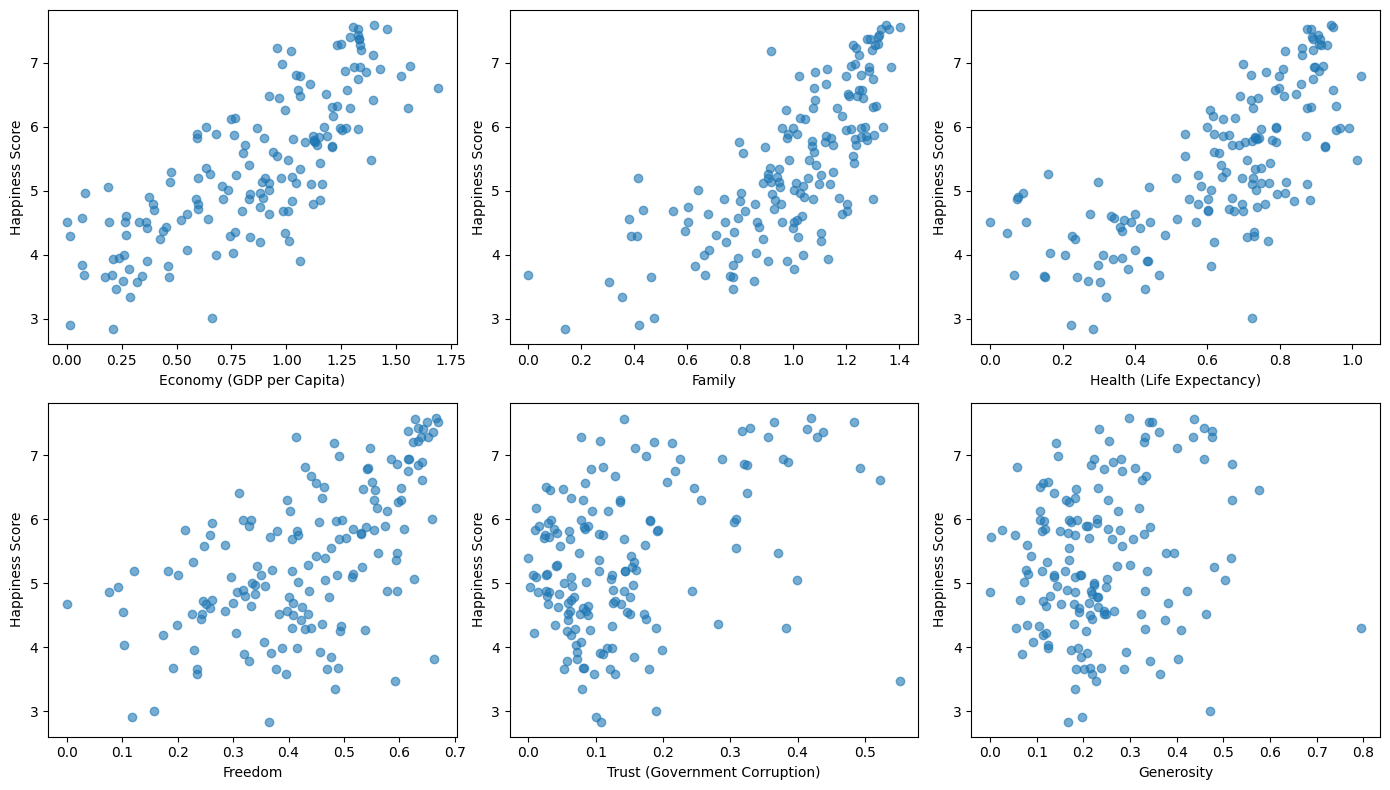

In [56]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), features):
    ax.scatter(df[col], y, alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel("Happiness Score")
plt.tight_layout()
plt.show()

In [57]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(len(X_train), len(X_test))

126 32


In [58]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [59]:
def evaluate(model, name):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

results = [
    evaluate(DummyRegressor(strategy="mean"), "Baseline (mean)"),
    evaluate(LinearRegression(), "Linear Regression"),
    evaluate(RandomForestRegressor(n_estimators=200, random_state=42), "Random Forest"),
]
results_df = pd.DataFrame(results).round(3)
results_df

,model,MAE,RMSE,R2
0,Baseline (mean),1.029,1.194,-0.005
1,Linear Regression,0.402,0.492,0.829
2,Random Forest,0.432,0.522,0.808


In [60]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
for name, model in [("Linear Regression", LinearRegression()),
                    ("Random Forest", RandomForestRegressor(n_estimators=200, random_state=42))]:
    s = cross_val_score(model, X, y, cv=kf, scoring="r2")
    print(name, s.round(3), "среднее:", s.mean().round(3))

Linear Regression [0.829 0.761 0.722 0.684 0.705] среднее: 0.74
Random Forest [0.791 0.751 0.736 0.723 0.618] среднее: 0.724


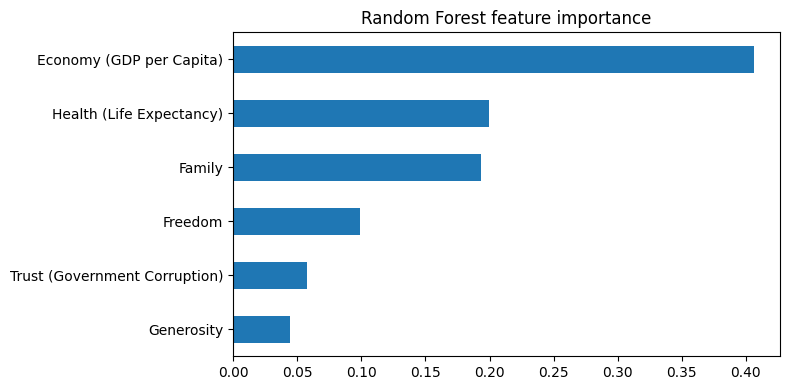

Economy (GDP per Capita)         0.406
Health (Life Expectancy)         0.200
Family                           0.194
Freedom                          0.099
Trust (Government Corruption)    0.057
Generosity                       0.044
dtype: float64


In [61]:
rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(8, 4), title="Random Forest feature importance")
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False).round(3))

In [62]:
leaky_features = features + ["Dystopia Residual"]
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    df[leaky_features], y, test_size=0.2, random_state=42)
leaky = LinearRegression().fit(Xl_train, yl_train)
print("R2 с утечкой:", round(r2_score(yl_test, leaky.predict(Xl_test)), 3))

R2 с утечкой: 1.0
